# ME249 Fall 2026 - Project 2 - Task 2.1
**Data preparation for the genetic algorithm (CodeP2.1F26) and log-log plot of the boiling data**

* Cell 1: program CodeP2.1F26 (two data values corrected to match the Appendix, see header).
* Cell 2: figure style / output folders (added).
* Cell 3: Task 2.1(a) - automatic comparison of the original skeleton data and of the corrected array with the Appendix.
* Cell 4: Task 2.1(b) - log-log plot of heat flux vs. superheat for g = 0.098 and 9.8 m/s2 with power-law fits.

In [1]:
'''>>>>> start CodeP2.1F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.1 / 2.2:
      - two data values corrected to match the Appendix listing of the project
        statement: row 0  q" 44.2 -> 44.1 W/cm2,  row 6  superheat 37.8 -> 37.5 C
      - everything else unchanged (red data with P other than 5.5 kPa still
        commented out, ND = NS = 45)'''

# version 3 print function
from __future__ import print_function
# seed the pseudorandom number generator
from random import random
from random import seed
# seed random number generator
seed(1)

#import math and numpy packages
import math
import numpy

%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8] # for square canvas


#import copy
from copy import copy, deepcopy


#create arrays
ydata = []
lydata = []

#Parameters for Evolution Loop
#set data parameters
ND = 45       #number of data vectors in array
DI = 5        #number of data items in vector
NS = 45       #total number of DNA strands

# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
# this is an array that is essentially a list of lists

#assembling data array
#store array where rows are data vectors
#[heat flux, superheat, gravity, surface tension parameter, pressure]

ydata =     [[44.1, 32.5, 0.098, 1.79, 5.5]]    # corrected (was 44.2)
ydata.append([47.4, 33.2, 0.098, 1.79, 5.5])
ydata.append([49.4, 34.2, 0.098, 1.79, 5.5])

ydata.append([59.2, 34.8, 0.098, 1.79, 5.5])
ydata.append([67.8, 36.3, 0.098, 1.79, 5.5])
ydata.append([73.6, 37.3, 0.098, 1.79, 5.5])
ydata.append([76.3, 37.5, 0.098, 1.79, 5.5])     # corrected (was 37.8)
ydata.append([85.3, 39.2, 0.098, 1.79, 5.5])
ydata.append([96.5, 39.3, 0.098, 1.79, 5.5])
ydata.append([111., 42.3, 0.098, 1.79, 5.5])
ydata.append([124., 43.5, 0.098, 1.79, 5.5])
ydata.append([136.2, 45.4, 0.098, 1.79, 5.5])

ydata.append([143.5, 46.7, 0.098, 1.79, 5.5])
ydata.append([154.6, 47.9, 0.098, 1.79, 5.5])
ydata.append([163.1, 48.6, 0.098, 1.79, 5.5])
ydata.append([172.8, 50.9, 0.098, 1.79, 5.5])
ydata.append([184.2, 51.7, 0.098, 1.79, 5.5])
ydata.append([203.7, 56.4, 0.098, 1.79, 5.5])

ydata.append([36.7, 30.2, 9.8, 1.79, 5.5])
ydata.append([55.1, 34.1, 9.8, 1.79, 5.5])
ydata.append([67.5, 35.3, 9.8, 1.79, 5.5])
ydata.append([78.0, 37.8, 9.8, 1.79, 5.5])
ydata.append([92.0, 38.1, 9.8, 1.79, 5.5])
ydata.append([120., 44.1, 9.8, 1.79, 5.5])
ydata.append([134.3, 46.9, 9.8, 1.79, 5.5])
ydata.append([150.3, 48.5, 9.8, 1.79, 5.5])
ydata.append([167., 49.2, 9.8, 1.79, 5.5])
ydata.append([184., 52.7, 9.8, 1.79, 5.5])
ydata.append([196.5, 53.1, 9.8, 1.79, 5.5])
'''
ydata.append([42.4, 28.0, 19.6, 1.79, 9.5])
ydata.append([48.7, 29.3, 19.6, 1.79, 9.5])
ydata.append([54.5, 29.6, 19.6, 1.79, 9.5])

ydata.append([62.1, 28.5, 19.6, 1.79, 9.5])
ydata.append([70.8, 30.5, 19.6, 1.79, 9.5])
ydata.append([73.7, 30.3, 19.6, 1.79, 9.5])
ydata.append([81.8, 30.6, 19.6, 1.79, 9.5])
ydata.append([91.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([103.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([119.1, 35.4, 19.6, 1.79, 9.5])
ydata.append([133.7, 36.8, 19.6, 1.79, 9.5])
ydata.append([139.9, 38.1, 19.6, 1.79, 9.5])
ydata.append([148.3, 39.1, 19.6, 1.79, 9.5])
ydata.append([157.0, 40.0, 19.6, 1.79, 9.5])
ydata.append([169.1, 42.2, 19.6, 1.79, 9.5])
ydata.append([179.2, 43.2, 19.6, 1.79, 9.5])
ydata.append([205.0, 46.0, 19.6, 1.79, 9.5])
'''
ydata.append([42.4, 29.7, 19.6, 1.79, 5.5])
ydata.append([48.7, 31.0, 19.6, 1.79, 5.5])
ydata.append([54.5, 31.2, 19.6, 1.79, 5.5])
ydata.append([70.8, 32.4, 19.6, 1.79, 5.5])
ydata.append([73.7, 31.4, 19.6, 1.79, 5.5])
ydata.append([81.8, 32.5, 19.6, 1.79, 5.5])
ydata.append([91.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([103.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([119.1, 37.2, 19.6, 1.79, 5.5])
ydata.append([133.7, 38.4, 19.6, 1.79, 5.5])
ydata.append([139.9, 39.7, 19.6, 1.79, 5.5])
ydata.append([148.3, 40.9, 19.6, 1.79, 5.5])
ydata.append([157.0, 41.6, 19.6, 1.79, 5.5])
ydata.append([169.1, 43.9, 19.6, 1.79, 5.5])
ydata.append([179.2, 45.0, 19.6, 1.79, 5.5])
ydata.append([205.0, 47.9, 19.6, 1.79, 5.5])
'''
ydata.append([77.0, 41.5, 9.8, 0.00, 7.0])
ydata.append([71.0, 40.5, 9.8, 0.00, 7.0])
ydata.append([66.0, 39.5, 9.8, 0.00, 7.0])
ydata.append([62.0, 38.5, 9.8, 0.00, 7.0])
ydata.append([42.0, 34.0, 9.8, 0.00, 7.0])
ydata.append([60.0, 37.5, 9.8, 0.00, 7.0])
ydata.append([53.0, 37.0, 9.8, 0.00, 7.0])

ydata.append([71.7, 36.4, 0.098, 1.71, 5.5])
ydata.append([81.5, 38.5, 0.098, 1.71, 5.5])
ydata.append([90.7, 39.5, 0.098, 1.71, 5.5])
ydata.append([103.3, 41.6, 0.098, 1.71, 5.5])
ydata.append([117.0, 43.1, 0.098, 1.71, 5.5])
ydata.append([138.6, 45.4, 0.098, 1.71, 5.5])
ydata.append([161.7, 47.9, 0.098, 1.71, 5.5])
ydata.append([207.5, 50.9, 0.098, 1.71, 5.5])
'''
# print the data array
print ('ydata =', ydata)
# Task 2.1(a): check of the array size and of a single array element
print ('number of rows =', len(ydata), ' ;  ydata[1][0] =', ydata[1][0], ' ;  ydata[6][1] =', ydata[6][1])


''' need deepcopy to create an array of the same size as ydata,
#   since this array is a list(rows) of lists (column entries)  '''
lydata = deepcopy(ydata)  # create array to store ln of data values


# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
#now store log values for data
for j in range(DI):
    for i in range(ND):
        lydata[i][j]=math.log(ydata[i][j]+0.000000000010)

#OK now have stored array of log values for data

#end CodeP2.1F26


ydata = [[44.1, 32.5, 0.098, 1.79, 5.5], [47.4, 33.2, 0.098, 1.79, 5.5], [49.4, 34.2, 0.098, 1.79, 5.5], [59.2, 34.8, 0.098, 1.79, 5.5], [67.8, 36.3, 0.098, 1.79, 5.5], [73.6, 37.3, 0.098, 1.79, 5.5], [76.3, 37.5, 0.098, 1.79, 5.5], [85.3, 39.2, 0.098, 1.79, 5.5], [96.5, 39.3, 0.098, 1.79, 5.5], [111.0, 42.3, 0.098, 1.79, 5.5], [124.0, 43.5, 0.098, 1.79, 5.5], [136.2, 45.4, 0.098, 1.79, 5.5], [143.5, 46.7, 0.098, 1.79, 5.5], [154.6, 47.9, 0.098, 1.79, 5.5], [163.1, 48.6, 0.098, 1.79, 5.5], [172.8, 50.9, 0.098, 1.79, 5.5], [184.2, 51.7, 0.098, 1.79, 5.5], [203.7, 56.4, 0.098, 1.79, 5.5], [36.7, 30.2, 9.8, 1.79, 5.5], [55.1, 34.1, 9.8, 1.79, 5.5], [67.5, 35.3, 9.8, 1.79, 5.5], [78.0, 37.8, 9.8, 1.79, 5.5], [92.0, 38.1, 9.8, 1.79, 5.5], [120.0, 44.1, 9.8, 1.79, 5.5], [134.3, 46.9, 9.8, 1.79, 5.5], [150.3, 48.5, 9.8, 1.79, 5.5], [167.0, 49.2, 9.8, 1.79, 5.5], [184.0, 52.7, 9.8, 1.79, 5.5], [196.5, 53.1, 9.8, 1.79, 5.5], [42.4, 29.7, 19.6, 1.79, 5.5], [48.7, 31.0, 19.6, 1.79, 5.5], [54.5, 3

In [2]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


In [3]:
'''(added) Task 2.1(a): check of the data array against the Appendix of the project statement'''
import re

# Appendix - data for Part 1 : [q", Tw-Tsat, g, gamma, P]  (77 rows, black + red text)
appendix = [[44.1, 32.5, 0.098, 1.79, 5.5], [47.4, 33.2, 0.098, 1.79, 5.5], [49.4, 34.2, 0.098, 1.79, 5.5], [59.2, 34.8, 0.098, 1.79, 5.5],
            [67.8, 36.3, 0.098, 1.79, 5.5], [73.6, 37.3, 0.098, 1.79, 5.5], [76.3, 37.5, 0.098, 1.79, 5.5], [85.3, 39.2, 0.098, 1.79, 5.5],
            [96.5, 39.3, 0.098, 1.79, 5.5], [111.0, 42.3, 0.098, 1.79, 5.5], [124.0, 43.5, 0.098, 1.79, 5.5], [136.2, 45.4, 0.098, 1.79, 5.5],
            [143.5, 46.7, 0.098, 1.79, 5.5], [154.6, 47.9, 0.098, 1.79, 5.5], [163.1, 48.6, 0.098, 1.79, 5.5], [172.8, 50.9, 0.098, 1.79, 5.5],
            [184.2, 51.7, 0.098, 1.79, 5.5], [203.7, 56.4, 0.098, 1.79, 5.5], [36.7, 30.2, 9.8, 1.79, 5.5], [55.1, 34.1, 9.8, 1.79, 5.5],
            [67.5, 35.3, 9.8, 1.79, 5.5], [78.0, 37.8, 9.8, 1.79, 5.5], [92.0, 38.1, 9.8, 1.79, 5.5], [120.0, 44.1, 9.8, 1.79, 5.5],
            [134.3, 46.9, 9.8, 1.79, 5.5], [150.3, 48.5, 9.8, 1.79, 5.5], [167.0, 49.2, 9.8, 1.79, 5.5], [184.0, 52.7, 9.8, 1.79, 5.5],
            [196.5, 53.1, 9.8, 1.79, 5.5], [42.4, 28.0, 19.6, 1.79, 9.5], [48.7, 29.3, 19.6, 1.79, 9.5], [54.5, 29.6, 19.6, 1.79, 9.5],
            [62.1, 28.5, 19.6, 1.79, 9.5], [70.8, 30.5, 19.6, 1.79, 9.5], [73.7, 30.3, 19.6, 1.79, 9.5], [81.8, 30.6, 19.6, 1.79, 9.5],
            [91.9, 34.5, 19.6, 1.79, 9.5], [103.9, 34.5, 19.6, 1.79, 9.5], [119.1, 35.4, 19.6, 1.79, 9.5], [133.7, 36.8, 19.6, 1.79, 9.5],
            [139.9, 38.1, 19.6, 1.79, 9.5], [148.3, 39.1, 19.6, 1.79, 9.5], [157.0, 40.0, 19.6, 1.79, 9.5], [169.1, 42.2, 19.6, 1.79, 9.5],
            [179.2, 43.2, 19.6, 1.79, 9.5], [205.0, 46.0, 19.6, 1.79, 9.5], [42.4, 29.7, 19.6, 1.79, 5.5], [48.7, 31.0, 19.6, 1.79, 5.5],
            [54.5, 31.2, 19.6, 1.79, 5.5], [70.8, 32.4, 19.6, 1.79, 5.5], [73.7, 31.4, 19.6, 1.79, 5.5], [81.8, 32.5, 19.6, 1.79, 5.5],
            [91.9, 36.3, 19.6, 1.79, 5.5], [103.9, 36.3, 19.6, 1.79, 5.5], [119.1, 37.2, 19.6, 1.79, 5.5], [133.7, 38.4, 19.6, 1.79, 5.5],
            [139.9, 39.7, 19.6, 1.79, 5.5], [148.3, 40.9, 19.6, 1.79, 5.5], [157.0, 41.6, 19.6, 1.79, 5.5], [169.1, 43.9, 19.6, 1.79, 5.5],
            [179.2, 45.0, 19.6, 1.79, 5.5], [205.0, 47.9, 19.6, 1.79, 5.5], [77.0, 41.5, 9.8, 0.0, 7.0], [71.0, 40.5, 9.8, 0.0, 7.0],
            [66.0, 39.5, 9.8, 0.0, 7.0], [62.0, 38.5, 9.8, 0.0, 7.0], [42.0, 34.0, 9.8, 0.0, 7.0], [60.0, 37.5, 9.8, 0.0, 7.0],
            [53.0, 37.0, 9.8, 0.0, 7.0], [71.7, 36.4, 0.098, 1.71, 5.5], [81.5, 38.5, 0.098, 1.71, 5.5], [90.7, 39.5, 0.098, 1.71, 5.5],
            [103.3, 41.6, 0.098, 1.71, 5.5], [117.0, 43.1, 0.098, 1.71, 5.5], [138.6, 45.4, 0.098, 1.71, 5.5], [161.7, 47.9, 0.098, 1.71, 5.5],
            [207.5, 50.9, 0.098, 1.71, 5.5]]
black = list(range(0, 29)) + list(range(46, 62))      # rows printed in black in the Appendix (P = 5.5 kPa, gamma = 1.79)

# (1) rows of the ORIGINAL skeleton file CodeP2.1F26 (active and commented-out lines)
src = ''.join(json.load(open('../CodeP2.1F26.ipynb'))['cells'][0]['source'])
block = src.split('ydata =     [[')[1].split('# print the data array')[0]
skel = [[float(x) for x in r.split(',')] for r in re.findall(r'\[([-\d., ]+)\]', '[' + block)]
print('original skeleton: %d rows   Appendix: %d rows' % (len(skel), len(appendix)))
for i, (a, b) in enumerate(zip(skel, appendix)):
    if any(abs(x - y) > 1e-9 for x, y in zip(a, b)):
        print('   row %2d differs:  skeleton %s   Appendix %s' % (i, a, b))

# (2) corrected array used in this program (45 black rows)
ndiff = sum(any(abs(x - y) > 1e-9 for x, y in zip(ydata[i], appendix[j])) for i, j in enumerate(black))
print('corrected ydata: %d rows, %d differences with the black rows of the Appendix' % (len(ydata), ndiff))
print('single element check: ydata[3][0] =', ydata[3][0], ' (Appendix row 4, heat flux 59.2 W/cm2)')


original skeleton: 77 rows   Appendix: 77 rows
   row  0 differs:  skeleton [44.2, 32.5, 0.098, 1.79, 5.5]   Appendix [44.1, 32.5, 0.098, 1.79, 5.5]
   row  6 differs:  skeleton [76.3, 37.8, 0.098, 1.79, 5.5]   Appendix [76.3, 37.5, 0.098, 1.79, 5.5]
corrected ydata: 45 rows, 0 differences with the black rows of the Appendix
single element check: ydata[3][0] = 59.2  (Appendix row 4, heat flux 59.2 W/cm2)


g =  0.098 m/s2 : 18 points, q" = 1.7285e-03 (Tw-Tsat)^2.940
g =  9.800 m/s2 : 11 points, q" = 2.9470e-03 (Tw-Tsat)^2.799


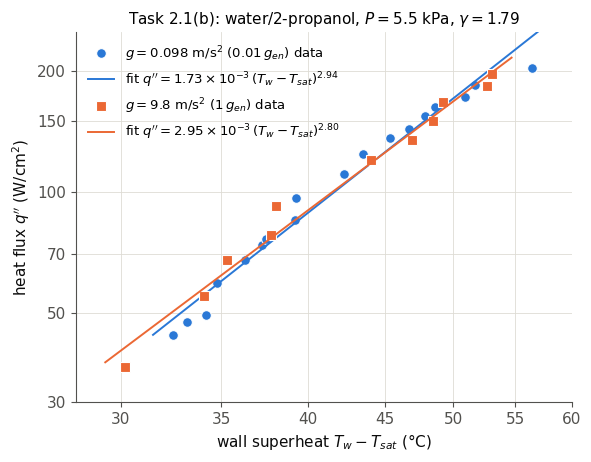

Tw-Tsat = 32.0 C : q"(0.098) =   46.0  q"(9.8) =   48.2  ratio q"(9.8)/q"(0.098) = 1.047
Tw-Tsat = 40.0 C : q"(0.098) =   88.7  q"(9.8) =   90.0  ratio q"(9.8)/q"(0.098) = 1.014
Tw-Tsat = 50.0 C : q"(0.098) =  170.9  q"(9.8) =  168.0  ratio q"(9.8)/q"(0.098) = 0.983


In [4]:
'''(added) Task 2.1(b): log-log plot of heat flux versus wall superheat for g = 0.098 and 9.8 m/s2
   (first two groups of the Appendix, P = 5.5 kPa, gamma = 1.79) + power-law fit q" = C (Tw-Tsat)^m
   of each group (least squares on ln q" vs ln(Tw-Tsat)) to quantify the trends'''
yarr = numpy.array(ydata)
fits21 = {}
fig, ax = plt.subplots(figsize=(6.4, 4.8))
for c, (gval, lab) in enumerate([(0.098, r'$g = 0.098$ m/s$^2$ ($0.01\,g_{en}$)'), (9.8, r'$g = 9.8$ m/s$^2$ ($1\,g_{en}$)')]):
    sel = yarr[:, 2] == gval
    dT, qpp = yarr[sel, 1], yarr[sel, 0]
    m, lnC = numpy.polyfit(numpy.log(dT), numpy.log(qpp), 1)
    fits21[str(gval)] = dict(m=m, C=math.exp(lnC), npts=int(sel.sum()))
    ax.loglog(dT, qpp, MK[c], color=C[c], ms=7, mec='white', mew=0.8, label=lab + ' data')
    xx = numpy.linspace(dT.min() * 0.97, dT.max() * 1.03, 50)
    ax.loglog(xx, math.exp(lnC) * xx**m, '-', color=C[c], lw=1.4,
              label=r'fit $q^{\prime\prime} = %s\,(T_w-T_{sat})^{%.2f}$' % (sci(math.exp(lnC)), m))
    print('g = %6.3f m/s2 : %2d points, q" = %.4e (Tw-Tsat)^%.3f' % (gval, sel.sum(), math.exp(lnC), m))
ax.set_xlabel(r'wall superheat $T_w - T_{sat}$ (°C)')
ax.set_ylabel(r'heat flux $q^{\prime\prime}$ (W/cm$^2$)')
ax.set_xlim(28, 60); ax.set_ylim(30, 250)
ax.set_xticks([30, 35, 40, 45, 50, 55, 60]); ax.set_xticklabels(['30', '35', '40', '45', '50', '55', '60'])
ax.set_yticks([30, 50, 70, 100, 150, 200]); ax.set_yticklabels(['30', '50', '70', '100', '150', '200'])
ax.minorticks_off()
ax.legend(loc='upper left')
ax.set_title(r'Task 2.1(b): water/2-propanol, $P = 5.5$ kPa, $\gamma = 1.79$')
savefig('t21_loglog')

# ratio of the two fitted curves at a few superheats (gravity effect at fixed superheat)
for dTv in [32., 40., 50.]:
    q1 = fits21['0.098']['C'] * dTv**fits21['0.098']['m']
    q2 = fits21['9.8']['C'] * dTv**fits21['9.8']['m']
    print('Tw-Tsat = %4.1f C : q"(0.098) = %6.1f  q"(9.8) = %6.1f  ratio q"(9.8)/q"(0.098) = %.3f' % (dTv, q1, q2, q2 / q1))
json.dump(fits21, open(RESDIR + 'task21.json', 'w'), indent=1)
